# 단기 이상 탐지 — 최신 결과

단일 IF·K-means·LOF의 최신 전체 파이프라인 결과다. 정상 참고·시계열 피처·경보 보정을 포함한다. 개발 벤치마크를 반복 사용했으므로 외부 블라인드 성능이 아니다. 아래 셀은 집계 JSON만 읽으며 원본·벤치마크·모델 로드가 필요 없다.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'latest_inventory.json').exists())
read = lambda p: json.loads((ROOT/p).read_text(encoding='utf-8'))
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':11,'axes.spines.top':False,'axes.spines.right':False})
colors = ['#2563eb','#d97706','#059669']

s = read('reports/shared_model_v7/release/summary.json')
alg = ['if','kmeans','lof']
names = {'if':'IF','kmeans':'K-means','lof':'LOF'}
metrics = ['accuracy','precision','recall','f1']
overall = pd.DataFrame(s['pooled']).set_index('method').loc[alg]
display((overall[metrics+['normal_false_positive_rate']]*100).round(3))

,accuracy,precision,recall,f1,normal_false_positive_rate
method,,,,,
if,94.007,90.326,73.001,80.745,1.626
kmeans,93.663,92.932,68.383,78.790,1.081
lof,93.809,89.597,72.441,80.111,1.749


## 1. 전체 성능

전체 분 판정의 혼동행렬을 합산했다. Accuracy는 전체 정답률, Precision은 경보 중 실제 이상 비율, Recall은 실제 이상 중 탐지 비율, F1은 Precision·Recall의 조화평균이다. FPR은 정상 중 잘못 경보한 비율이다.

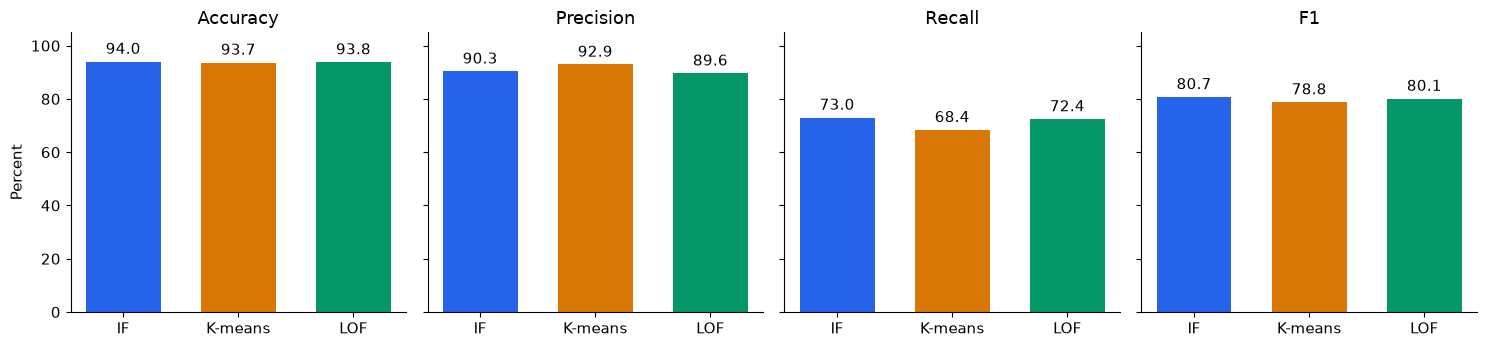

In [2]:
fig, axes = plt.subplots(1,4,figsize=(15,3.6),sharey=True)
for ax, metric in zip(axes,metrics):
    bars = ax.bar([names[a] for a in alg],overall[metric]*100,color=colors,width=.65)
    ax.bar_label(bars,fmt='%.1f',padding=3)
    ax.set(title=metric.capitalize(),ylim=(0,105),ylabel='Percent' if ax is axes[0] else '')
fig.tight_layout(); display(fig); plt.close(fig)

## 2. 시나리오별 차이

각 시나리오에 정상·이상 구간이 함께 포함된다. 모델마다 특화된 비교 기준과 통계 보정까지 포함한 관측 결과이며 알고리즘 자체의 보편적 순위를 뜻하지 않는다.

,scenario,method,accuracy,precision,recall,f1,normal_false_positive_rate
0,individual_delay,if,98.111,99.799,77.911,87.507,0.015
1,individual_delay,kmeans,97.166,99.912,66.680,79.981,0.005
2,individual_delay,lof,97.543,99.807,71.196,83.108,0.013
3,group_delay,if,96.784,86.952,92.675,89.722,2.483
4,group_delay,kmeans,97.787,90.584,95.299,92.882,1.769
5,group_delay,lof,96.686,85.706,93.760,89.552,2.792
6,time_burst,if,94.116,81.522,56.475,66.725,1.493
7,time_burst,kmeans,94.430,85.991,55.764,67.655,1.060
8,time_burst,lof,94.282,84.502,55.423,66.941,1.186
9,input_stop,if,95.650,95.333,76.414,84.832,0.708


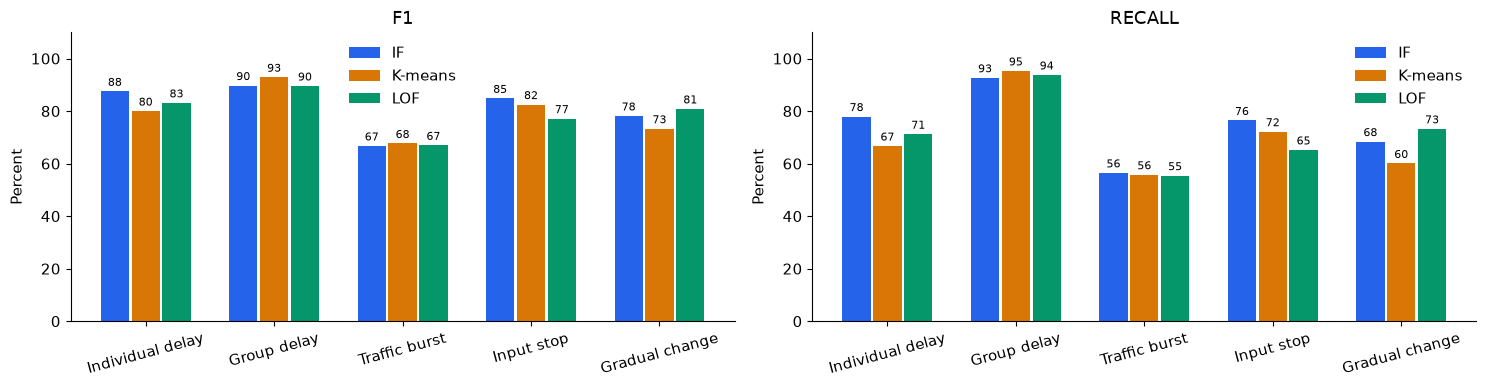

In [3]:
rows = [{'scenario':d['dataset'],**r} for d in s['datasets'] for r in d['metrics']]
task = pd.DataFrame(rows)
display(task[['scenario','method',*metrics,'normal_false_positive_rate']].assign(**{k:task[k]*100 for k in metrics+['normal_false_positive_rate']}).round(3))
order = [d['dataset'] for d in s['datasets']]
labels = {'individual_delay':'Individual delay','group_delay':'Group delay','time_burst':'Traffic burst','input_stop':'Input stop','gradual_degradation':'Gradual change'}
fig, axes = plt.subplots(1,2,figsize=(15,4))
for ax, metric in zip(axes,['f1','recall']):
    x=np.arange(len(order))
    for j,a in enumerate(alg):
        values=task[task.method.eq(a)].set_index('scenario').loc[order,metric].to_numpy()*100
        bars=ax.bar(x+(j-1)*.24,values,width=.22,color=colors[j],label=names[a])
        ax.bar_label(bars,fmt='%.0f',padding=2,fontsize=8)
    ax.set(title=metric.upper(),ylim=(0,110),xticks=x,xticklabels=[labels[t] for t in order],ylabel='Percent')
    ax.tick_params(axis='x',rotation=15); ax.legend(frameon=False)
fig.tight_layout(); display(fig); plt.close(fig)

## 3. 점수 분포와 실제 경보선

점수 **1 초과**가 경보다. 확률이 아니며 0~1 범위로 제한되지 않는다. 정상/이상은 각 집단 내부 백분율로 표시한다. 가독성을 위해 −1 미만·3 초과는 양 끝 막대에 합산했으며 표에 해당 건수를 표시한다. 행을 버리거나 정답을 확장하지 않았다.

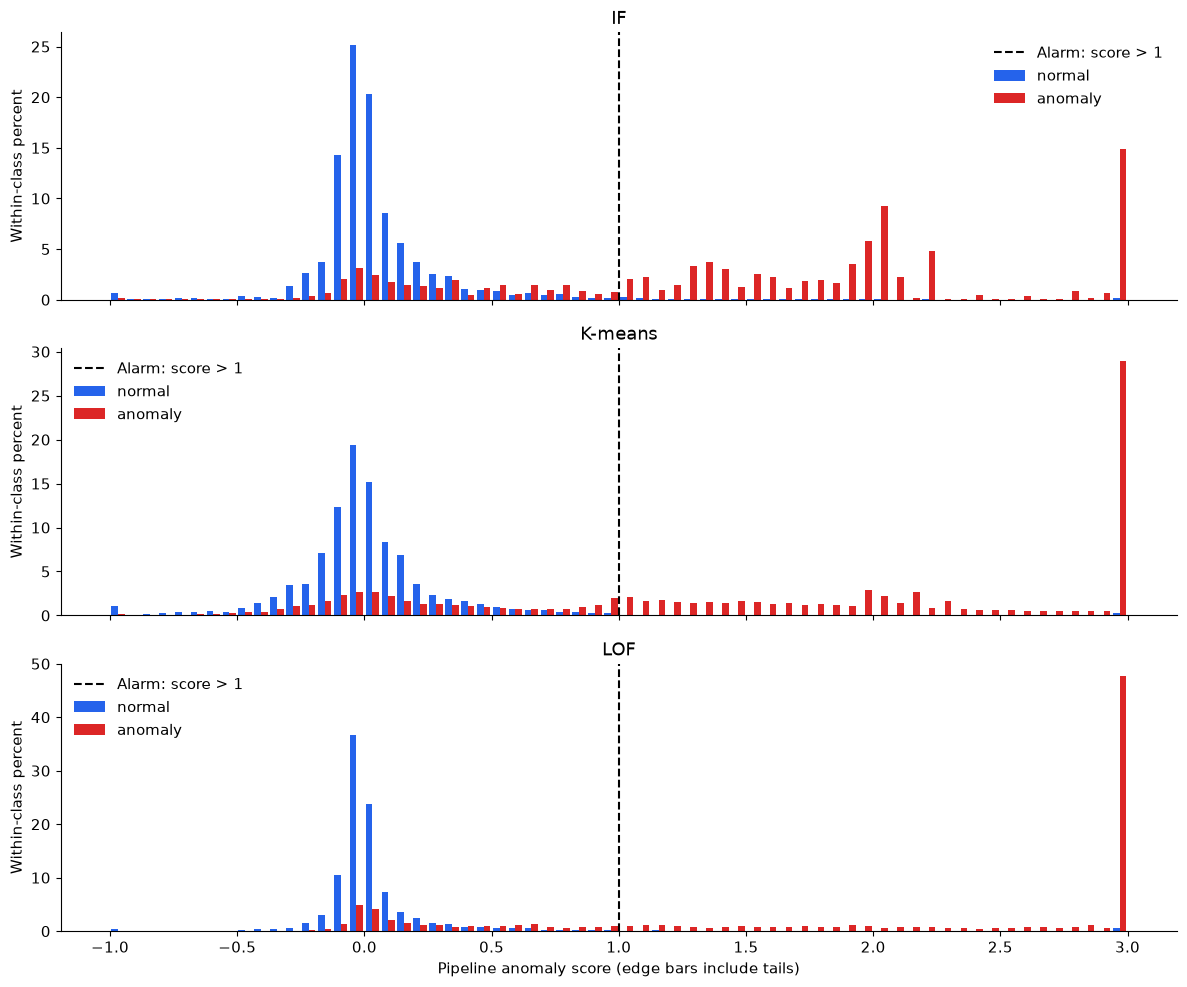

,model,label,rows,below_-1,above_3
0,IF,normal,1596121,10105,2247
1,IF,anomaly,331851,556,48895
2,K-means,normal,1596121,16937,4193
3,K-means,anomaly,331851,524,94413
4,LOF,normal,1596121,5368,9003
5,LOF,anomaly,331851,278,155491


In [4]:
h=read('reports/shared_model_v7/release/score_histograms.json')
edges=np.array(h['edges']); centers=(edges[:-1]+edges[1:])/2; width=np.diff(edges)[0]
fig,axes=plt.subplots(3,1,figsize=(12,10),sharex=True)
tails=[]
for ax,a in zip(axes,alg):
    for label,color,shift in [('normal','#2563eb',-.21),('anomaly','#dc2626',.21)]:
        records=[r[label] for r in h['models'][a]]
        counts=np.sum([r['counts'] for r in records],axis=0); total=sum(r['n'] for r in records)
        ax.bar(centers+shift*width,100*counts/total,width=.42*width,color=color,label=label)
        tails.append({'model':names[a],'label':label,'rows':total,'below_-1':sum(r['below_plot_range'] for r in records),'above_3':sum(r['above_plot_range'] for r in records)})
    ax.axvline(1,color='black',linestyle='--',label='Alarm: score > 1')
    ax.set(title=names[a],ylabel='Within-class percent'); ax.legend(frameon=False)
axes[-1].set_xlabel('Pipeline anomaly score (edge bars include tails)')
fig.tight_layout(); display(fig); plt.close(fig)
display(pd.DataFrame(tails))

## 핵심 해석

- IF는 개별 지연, K-means는 집단 지연, LOF는 점진적 악화에서 상대적인 F1 강점이 관측됐다.
- 낮은 FPR과 높은 Precision만으로 이상 누락이 적다고 말할 수 없다. Recall도 함께 확인한다.
- 입력 중단·폭주는 Process 한 행만으로 판단하지 않고 수집 확인과 연속 실행 건수 이력이 필요하다.
- 새 데이터에 재학습한 baseline은 별도 모델이며 이 성능표를 승계하지 않는다.
- 피처 중요도 상세는 `code/shared_model_v7/feature_importance.ipynb`, 입력·재학습은 상위 INTEGRATION/REPRODUCING 문서에 있다.